In [1]:
%load_ext autoreload
%autoreload 2

# I. Modeling

Since our model is designed to encode the attributes of each entity (**type, size, color, and orientation angle**) we adopt a **multi-task CNN encoder architecture**. 

The encoder is jointly trained to predict these attributes from the visual input (crops) and to learn a compact **latent representation**. 

This latent vector will be combined with the entity’s **spatial and structural information** (**problem ID, panel ID, and bounding boxes**).

The resulting feature representation is then provided to the **graph construction module**, which uses these attributes to construct the graph representation that will ultimately be processed by the **GNN**.



## 1. Visual Encoder (CNN)

we choose to use a multi-task CNN architecture 
<div align="center">
  <img src="../assets/images/MT-CNN_GB.drawio.png" alt="Alt text">
</div>

**Getting the data**

In [ ]:
# # test the output shape of the model
# # we need first to grab the data 

# import torch
# from hri_gnn.datasets import RavenDataset , gnn_flat_collate
# from torch.utils.data import DataLoader

# # Fixing the seeds
# torch.manual_seed(42)
# torch.cuda.manual_seed(42)

# # Train dataset
# train_dataset = RavenDataset(
#     dataset="raven-20000",
#     split="train",
#     percentage_limit=0.0025
# )
# # Test dataset
# test_dataset = RavenDataset(
#     dataset="raven-20000",
#     split="test",
#     percentage_limit=0.0025
# )
# # Validation dataset
# val_dataset = RavenDataset(
#     dataset="raven-20000",
#     split="val",
#     percentage_limit=0.0025
# )
# # Train DataLoader
# train_dataloader = DataLoader(
#     dataset=train_dataset,
#     batch_size=5,
#     shuffle=True,
#     collate_fn= gnn_flat_collate
# )
# # Test DataLoader
# test_dataloader = DataLoader(
#     dataset=test_dataset,
#     batch_size=5,
#     shuffle=False,
#     collate_fn= gnn_flat_collate
# )
# # Validation DataLoader
# val_dataloader = DataLoader(
#     dataset=val_dataset,
#     batch_size=5,
#     shuffle=False,
#     collate_fn= gnn_flat_collate
# )


In [ ]:
# # Checking datasets lengths 
# len(train_dataset) ,len(val_dataset), len(test_dataset)

(203, 67, 67)

In [ ]:
# # Instanciating the model

# import torch
# from hri_gnn.models.cnn_encoder import RavenCnnEncoder

# # Fixing the seeds
# torch.manual_seed(42)
# torch.cuda.manual_seed(42)

# # make the code device agnostic 
# device = "cuda" if torch.cuda.is_available() else "cpu"
# # printing the device
# print(f"the available device is:{device}")

# cnn_encoder = RavenCnnEncoder().to(device)

the available device is:cuda


**Training the model**

In [ ]:
# import torch 
# from hri_gnn.training.trainer import Trainer
# from hri_gnn.losses import CompositeLoss
# from hri_gnn.metrics import TrainingTimer

# criterion = CompositeLoss()
# optimizer = torch.optim.Adam(params=cnn_encoder.parameters(),lr=1e-4)
# with TrainingTimer(model= cnn_encoder) as train_timer:
#     raven_trainer = Trainer(
#                         model=cnn_encoder, 
#                         optimizer=optimizer, 
#                         criterion=criterion,
#                         metrics_detials=True,
#                         loss_details=True)
#     history = raven_trainer.fit(train_dataloader,test_dataloader,epochs=20, verbose=False , checkpoint_dir="C://Users//dhias//workspaces//these//HRI-GNN//outputs//checkpoints")
# model_training_time = train_timer.elapsed


start training model: RavenCnnEncoder...
No device provided, Trainer will use: cuda
No device was specified, CompositeMetric is setting device to: cuda


  0%|          | 0/20 [00:00<?, ?it/s]

Epoque 1/20: 
- Train (Test) losses: loss: 7.9206 (7.3910) - loss_type: 1.6875 (1.5952) - loss_size: 1.7326 (1.5522) - loss_color: 2.2978 (2.1333) - loss_angle: 2.2026 (2.1103) - 
Epoque 2/20: 
- Train (Test) losses: loss: 7.1590 (6.9794) - loss_type: 1.5250 (1.5032) - loss_size: 1.4337 (1.3780) - loss_color: 2.1173 (2.0276) - loss_angle: 2.0830 (2.0706) - 
Epoque 3/20: 
- Train (Test) losses: loss: 6.6732 (6.4618) - loss_type: 1.4302 (1.3462) - loss_size: 1.2434 (1.1863) - loss_color: 1.9642 (1.8922) - loss_angle: 2.0354 (2.0372) - 
Epoque 4/20: 
- Train (Test) losses: loss: 6.1853 (5.9864) - loss_type: 1.3111 (1.2709) - loss_size: 1.1058 (1.0458) - loss_color: 1.7977 (1.7367) - loss_angle: 1.9708 (1.9330) - 
Epoque 5/20: 
- Train (Test) losses: loss: 5.7087 (5.4130) - loss_type: 1.2128 (1.1221) - loss_size: 0.9871 (0.9137) - loss_color: 1.6373 (1.5809) - loss_angle: 1.8715 (1.7964) - 
  > Checkpoint saved: C://Users//dhias//workspaces//these//HRI-GNN//outputs//checkpoints\checkpoint_

In [ ]:
# validation_result = raven_trainer.validate(val_dataloader=val_dataloader)


Validating the model...:   0%|          | 0/14 [00:00<?, ?it/s]

{'val_loss': 2.494952780859811,
 'val_loss_type': 0.3484895740236555,
 'val_loss_size': 0.23706668881433351,
 'val_loss_color': 0.827399879693985,
 'val_loss_angle': 1.0819966452462333,
 'val_accuracy': 0.7431067717926843,
 'val_precision': 0.7647469245961734,
 'val_recall': 0.7431067717926843,
 'val_f1': 0.7199506546769824,
 'val_accuracy_type': 0.8480923473834991,
 'val_accuracy_size': 0.9296404293605259,
 'val_accuracy_color': 0.6115762974534716,
 'val_accuracy_angle': 0.5831180129732404,
 'val_precision_type': 0.8952850529125759,
 'val_precision_size': 0.9280977589743478,
 'val_precision_color': 0.6343050428799221,
 'val_precision_angle': 0.6012998436178479,
 'val_recall_type': 0.8480923473834991,
 'val_recall_size': 0.9296404293605259,
 'val_recall_color': 0.6115762974534716,
 'val_recall_angle': 0.5831180129732404,
 'val_f1_type': 0.8276347688266209,
 'val_f1_size': 0.9243579804897308,
 'val_f1_color': 0.5794306738036019,
 'val_f1_angle': 0.5483791955879757,
 'val_num_of_crops': 

In [ ]:
# from hri_gnn.metrics import CompositeMetric
# from hri_gnn.visualization import oracle

# composite_metrics_fn = CompositeMetric()
# confusion_matrix_dict = composite_metrics_fn.compute_confusion_matrix(validation_result['val_y_logits'],validation_result['val_y_true'])

# oracle.plot_confusion_matrix(confusion_matrix_dict)


No device was specified, CompositeMetric is setting device to: cuda


NameError: name 'plot_confusion_matrix' is not defined

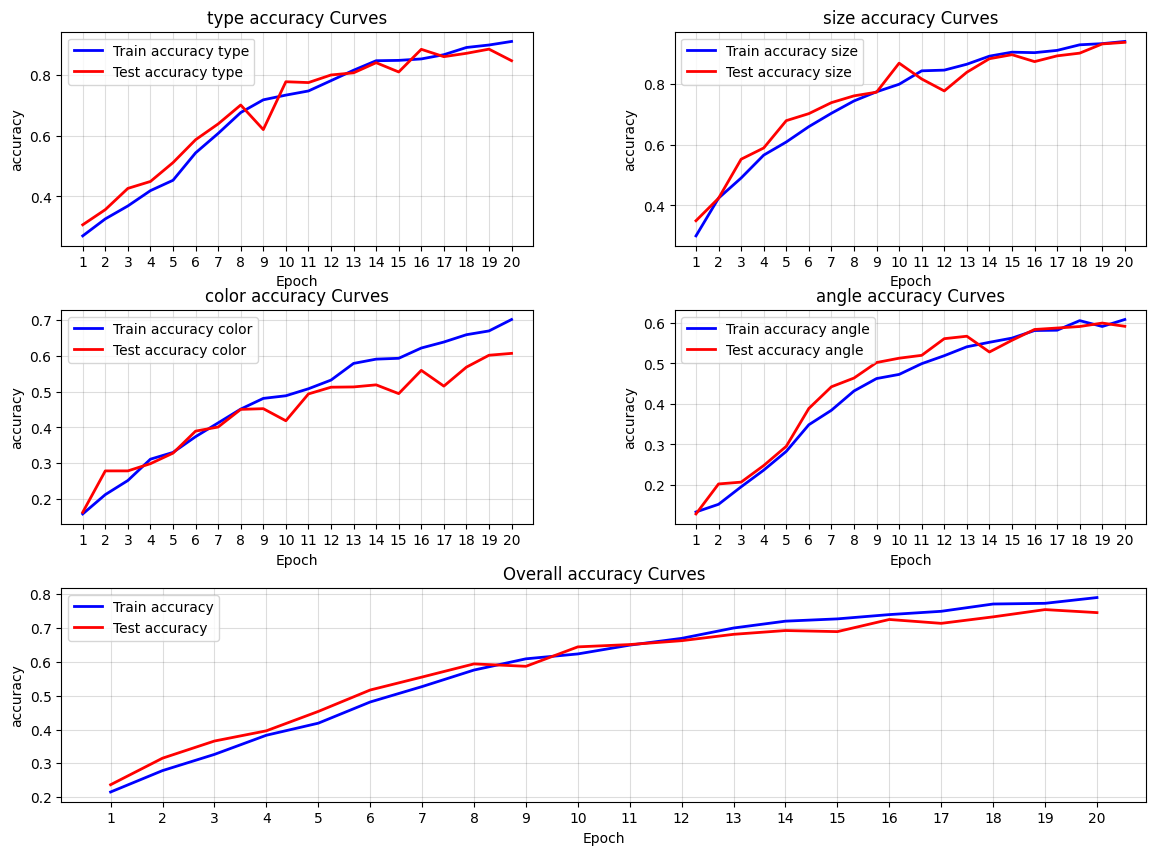

In [ ]:
# from hri_gnn.visualization import oracle

# oracle.plot_metric_curves(history, 'accuracy', None)


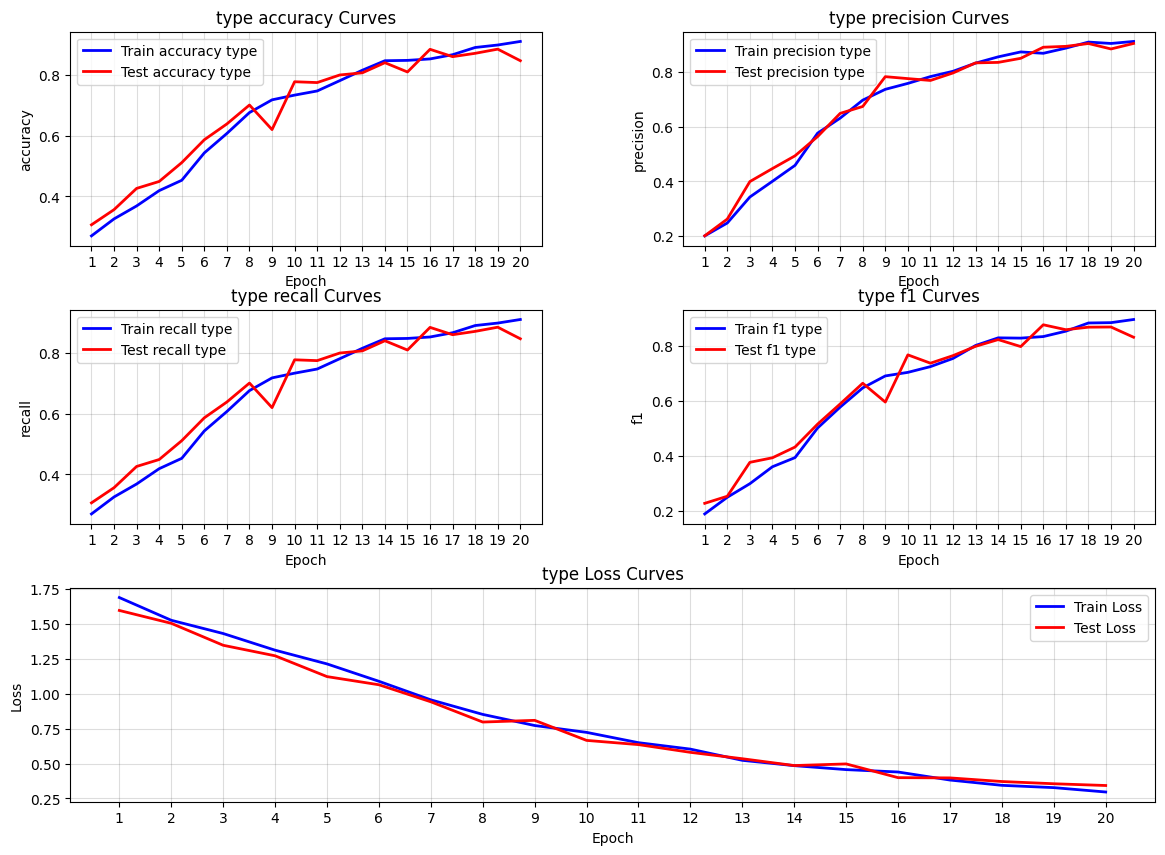

In [ ]:
# oracle.plot_attribute_metrics_curves(history, 'type', None)

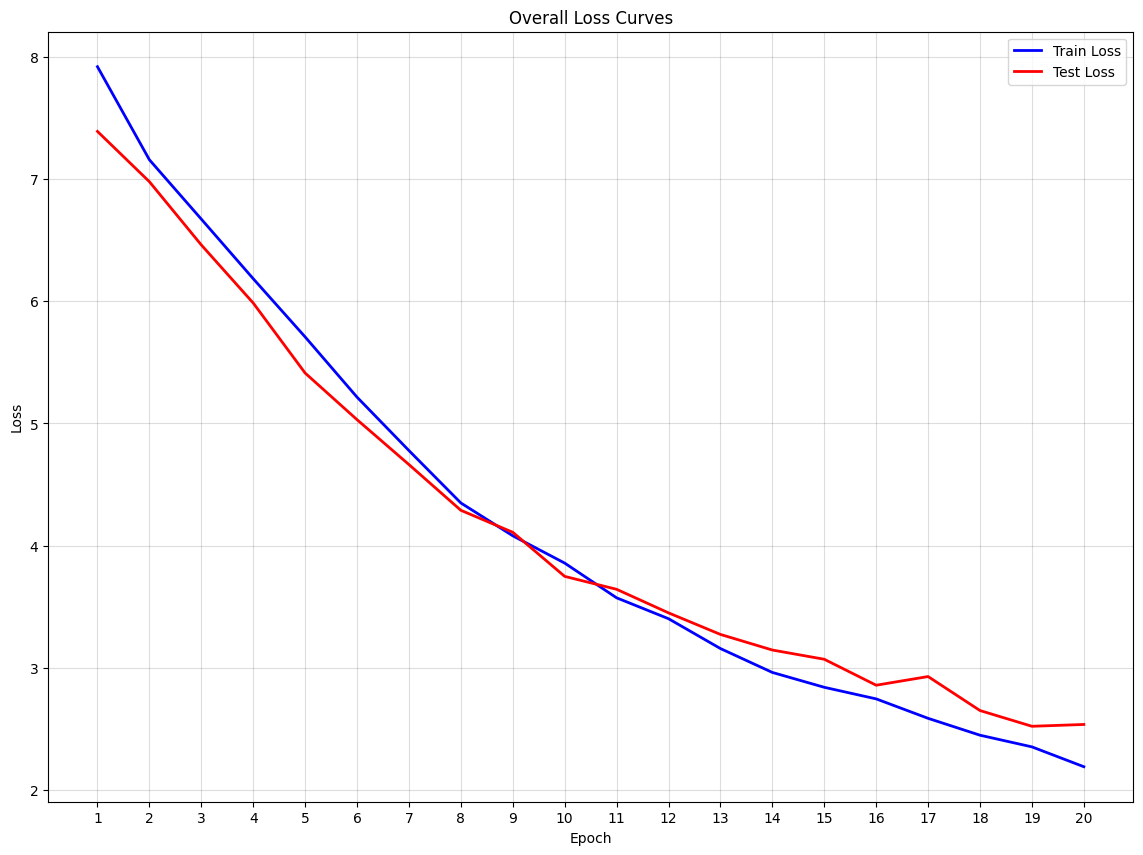

In [ ]:

# # plot the overall loss curves

# import matplotlib.pyplot as plt 

# epochs = range(1, len(history['train_loss']) + 1)

# fig, ax = plt.subplots(figsize=(14, 10))
# ax.plot(epochs, history['train_loss'],color='blue',linewidth=2, label='Train Loss')
# ax.plot(epochs, history['test_loss'], color='red', linewidth=2, label='Test Loss')
# ax.set_title('Overall Loss Curves')
# ax.set_xlabel('Epoch')
# ax.set_ylabel('Loss')
# ax.set_xticks(epochs)
# ax.legend()
# ax.grid(True, alpha=0.2, color='#555')
# plt.show()



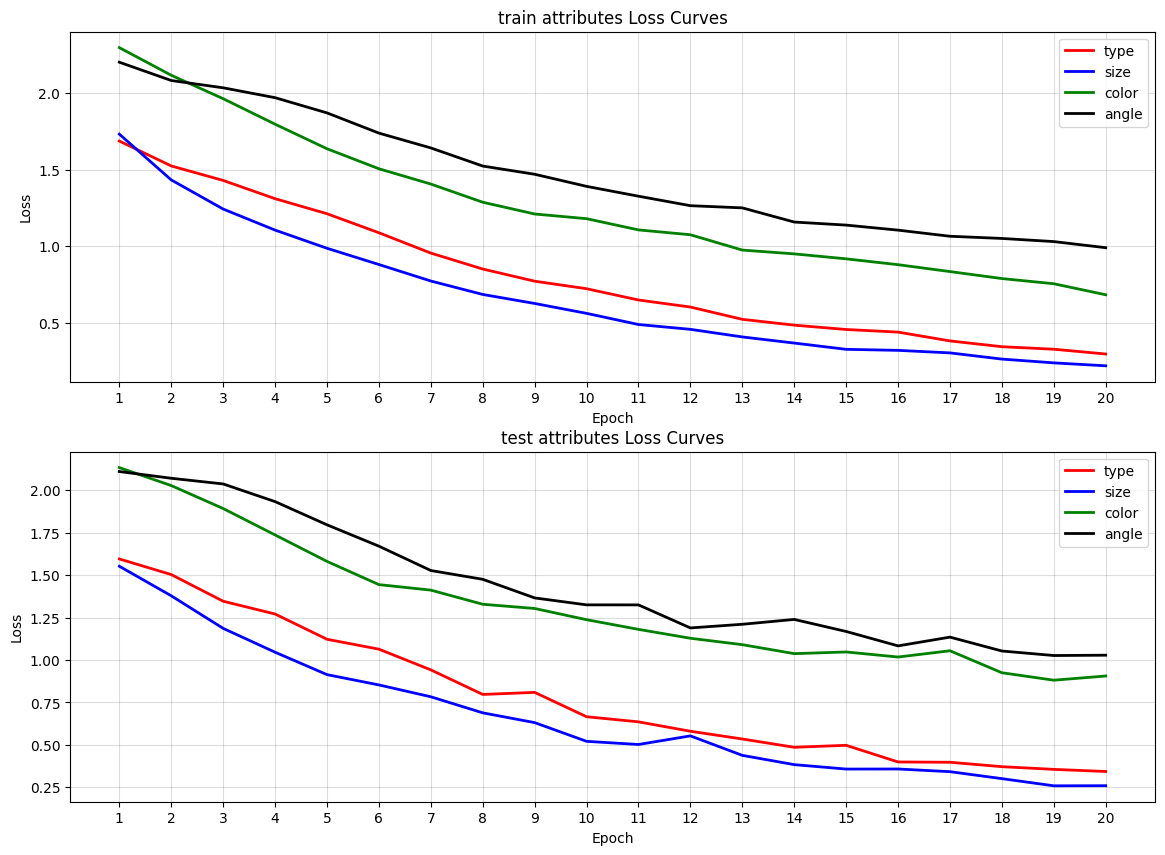

In [ ]:
# # plot all attributes train and loss curves
# split=['train', 'test']
# colors = ['red', 'blue', 'green', 'black']
# attributes = ['type', 'size', 'color', 'angle']

# fig, axes = plt.subplots(nrows=2, ncols=1,figsize=(14,10))
# for ax, split in zip(axes.flat, split):
#     for attribute, color in zip(attributes,colors):
#         ax.plot(epochs, history[f'{split}_loss_{attribute}'],color=color,linewidth=2, label=f'{attribute}')
#         ax.set_title(f'{split} attributes Loss Curves')
#         ax.set_xlabel('Epoch')
#         ax.set_ylabel('Loss')
#         ax.set_xticks(epochs)
#         ax.legend()
#         ax.grid(True, alpha=0.2, color='#555')

In [1]:
# plot accuracy, precision, recall and f1 


In [ ]:
from hri_gnn.training import train

DATASET_NAME = "raven-20000"
PERCENTAGE_TO_USE = 0.05
NB_EPOCHS = 35
BATCH_SIZE = 5
LEARNING_RATE = 1e-4

training_history, validation_results ,model_training_time = train.run_training(
                                                                    DATASET_NAME,
                                                                    PERCENTAGE_TO_USE,
                                                                    NB_EPOCHS,
                                                                    BATCH_SIZE,
                                                                    LEARNING_RATE
                                                                    )

Device : cuda
  GPU : NVIDIA GeForce RTX 5060 Laptop GPU

Loading dataset : raven-20000
  Percentage to use : 0.25%

Batch size : 5
Train dataset loaded : 203 problems
Val dataset loaded : 67 problems
Test dataset loaded : 67 problems

Modele : RavenCnnEncoder (164,638 parametres)

Optimizer : Adam
 Learning rate : 0.0001
 Loss : CompositeLoss 
 Metrics : CompositeMetric
epochs=2, batch_size=5, lr=0.0001
start training model: RavenCnnEncoder...


  0%|          | 0/2 [00:00<?, ?it/s]

Epoque 1/2: 
- Train (Test) losses: loss: 7.7608 (7.2133) - loss_type: 1.6788 (1.5720) - loss_size: 1.6153 (1.4194) - loss_color: 2.3108 (2.1159) - loss_angle: 2.1559 (2.1060) - 
- Train (Test) Metrics :accuracy: 0.2250 (0.2728) - precision: 0.1741 (0.2517) - recall: 0.2250 (0.2728) - f1: 0.1528 (0.1984) - accuracy_type: 0.2506 (0.3139) - accuracy_size: 0.3423 (0.4271) - accuracy_color: 0.1573 (0.2013) - accuracy_angle: 0.1497 (0.1487) - precision_type: 0.2081 (0.3382) - precision_size: 0.2992 (0.4261) - precision_color: 0.0797 (0.1416) - precision_angle: 0.1092 (0.1009) - recall_type: 0.2506 (0.3139) - recall_size: 0.3423 (0.4271) - recall_color: 0.1573 (0.2013) - recall_angle: 0.1497 (0.1487) - f1_type: 0.1767 (0.2231) - f1_size: 0.2664 (0.3449) - f1_color: 0.0816 (0.1217) - f1_angle: 0.0865 (0.1038) - 
  > Checkpoint saved: C:\Users\dhias\workspaces\these\HRI-GNN\outputs\checkpoints\RavenCnnEncoder-checkpoint_epoch_1.pth
Epoque 2/2: 
- Train (Test) losses: loss: 6.9869 (6.6890) - lo

Validating the model...:   0%|          | 0/14 [00:00<?, ?it/s]


Validation finished!....
Number of crops: 2799 | Number of batches: 14


  RESULTS ON VALIDATION SET  
 Number: 
  - Crops   : 2799 
  - Batches : 14
  Loss   : 6.6482
  Accuracy : 32.82%
  Precision           : 0.3105
  Recall           : 0.3282
  F1 score          : 0.2538
-------------- DETAILED LOSSES ---------------
  Type Loss    : 1.5164
  Size Loss    : 1.2089
  Color Loss   : 1.9255
  Angle Loss   : 1.9973
------------- DETAILED ACCURACIES -------------
  Type Accuracy : 33.70%
  Size Accuracy : 54.51%
  Color Accuracy : 21.61%
  Angle Accuracy : 21.47%
-------------- DETAILED PRECISIONS -------------
  Type Precision     : 0.2946
  Size Precision     : 0.5832
  Color Precision    : 0.1329
  Angle Precision    : 0.2314
-------------- DETAILED RECALLS ---------------
  Type Recall     : 0.3370
  Size Recall     : 0.5451
  Color Recall    : 0.2161
  Angle Recall    : 0.2147
------------- DETAILED F1 SCORES --------------
  Type F1 score     : 0.1988
  Size F1 score     : 0.5175

c:\Users\dhias\DevTools\miniconda3\envs\nsc\Lib\site-packages\mlxtend\plotting\plot_confusion_matrix.py:102: RuntimeWarning: invalid value encountered in divide
  normed_conf_mat = conf_mat.astype("float") / total_samples


... (7 outputs left out)

c:\Users\dhias\DevTools\miniconda3\envs\nsc\Lib\site-packages\mlxtend\plotting\plot_confusion_matrix.py:102: RuntimeWarning: invalid value encountered in divide
  normed_conf_mat = conf_mat.astype("float") / total_samples



[OK] Confusion matrix for val color saved to C:\Users\dhias\workspaces\these\HRI-GNN\outputs\confusion_matrices\val\color_confusion_matrix.png

[OK] Confusion matrix for val angle saved to C:\Users\dhias\workspaces\these\HRI-GNN\outputs\confusion_matrices\val\angle_confusion_matrix.png


c:\Users\dhias\DevTools\miniconda3\envs\nsc\Lib\site-packages\mlxtend\plotting\plot_confusion_matrix.py:102: RuntimeWarning: invalid value encountered in divide
  normed_conf_mat = conf_mat.astype("float") / total_samples



[OK] Confusion matrix for val overall saved to C:\Users\dhias\workspaces\these\HRI-GNN\outputs\confusion_matrices\val\overall_confusion_matrix.png

[OK] type metric curves saved to C:\Users\dhias\workspaces\these\HRI-GNN\outputs\attributes_curves\type_metrics_curves.png

[OK] size metric curves saved to C:\Users\dhias\workspaces\these\HRI-GNN\outputs\attributes_curves\size_metrics_curves.png

[OK] color metric curves saved to C:\Users\dhias\workspaces\these\HRI-GNN\outputs\attributes_curves\color_metrics_curves.png

[OK] angle metric curves saved to C:\Users\dhias\workspaces\these\HRI-GNN\outputs\attributes_curves\angle_metrics_curves.png

[OK] Model saved : C:\Users\dhias\workspaces\these\HRI-GNN\outputs\models\raven_cnn_encoder_final.pth


In [3]:
for i in range(1,2+1):
    print(i)

1
2


In [ ]:
import numpy as np
from hri_gnn.config.const import ENTITY_ATTRIBUTES
[entity_value for entity_values in ENTITY_ATTRIBUTES.values() for entity_value in entity_values]

['none',
 'triangle',
 'square',
 'pentagon',
 'hexagon',
 'circle',
 0.4,
 0.5,
 0.6,
 0.7,
 0.8,
 0.9,
 255,
 224,
 196,
 168,
 140,
 112,
 84,
 56,
 28,
 0,
 -135,
 -90,
 -45,
 0,
 45,
 90,
 135,
 180]

In [4]:
text = "train_confusion_matrix_type"

if "confusion_matrix" in text:
    print("Found!")

Found!


In [34]:
import torch
from torchmetrics.classification import MulticlassConfusionMatrix  
target_type = torch.randint(0,6, size=(4,)).to(torch.float) # torch.tensor([2, 1, 0, 0])  

preds_type = torch.rand(size=(4,6))
# torch.tensor([[0.16, 0.26, 0.58],  
#                 [0.22, 0.61, 0.17],  
#                 [0.71, 0.09, 0.20],  
#                 [0.05, 0.82, 0.13]])  
metric = MulticlassConfusionMatrix(num_classes=6)

print(f"preds_type: {preds_type}, shape: {preds_type.shape}")
print(f"target_type: {target_type}, shape: {target_type.shape}")
metric(preds_type, target_type)  

preds_type: tensor([[0.4494, 0.1835, 0.1134, 0.9994, 0.9549, 0.4296],
        [0.5575, 0.3205, 0.3094, 0.8495, 0.2907, 0.2167],
        [0.9474, 0.9300, 0.9395, 0.4507, 0.1536, 0.6722],
        [0.0922, 0.0109, 0.8599, 0.6789, 0.4627, 0.5671]]), shape: torch.Size([4, 6])
target_type: tensor([4., 1., 2., 3.]), shape: torch.Size([4])


tensor([[0, 0, 0, 0, 0, 0],
        [0, 0, 0, 1, 0, 0],
        [1, 0, 0, 0, 0, 0],
        [0, 0, 1, 0, 0, 0],
        [0, 0, 0, 1, 0, 0],
        [0, 0, 0, 0, 0, 0]])

In [ ]:
import torch
conf_matrix = {}
A = torch.tensor([[0, 1], [1, 0]])
conf_matrix['A'] = A
B = torch.tensor([[3, 4, 5], [6, 7, 8]])
conf_matrix['B'] = B
C = torch.tensor(7)
conf_matrix['C'] = C
D = torch.tensor([1, 2, 3])
conf_matrix['D'] = D
E = torch.tensor([[4], [5], [6]])
conf_matrix['E'] = E

first_big = torch.block_diag(*conf_matrix.values())


tensor([[0, 1, 0, 0, 0, 0, 0, 0, 0, 0],
        [1, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 3, 4, 5, 0, 0, 0, 0, 0],
        [0, 0, 6, 7, 8, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 7, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 1, 2, 3, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 4],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 5],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 6]])

In [1]:
import json
from pathlib import Path
from hri_gnn.visualization import oracle

output_path = "C:/Users/dhias/workspaces/these/HRI-GNN/outputs"
json_path = Path(output_path) / "training_history.json"
with open(json_path, 'r', encoding='utf-8') as file:
    history = json.load(file)
save_path = Path(output_path)

oracle.plot_confusion_matrix_attri(history, save_path=save_path)


c:\Users\dhias\DevTools\miniconda3\envs\nsc\Lib\site-packages\mlxtend\plotting\plot_confusion_matrix.py:102: RuntimeWarning: invalid value encountered in divide
  normed_conf_mat = conf_mat.astype("float") / total_samples
c:\Users\dhias\DevTools\miniconda3\envs\nsc\Lib\site-packages\mlxtend\plotting\plot_confusion_matrix.py:102: RuntimeWarning: invalid value encountered in divide
  normed_conf_mat = conf_mat.astype("float") / total_samples


train type Confusion matrix saved to C:\Users\dhias\workspaces\these\HRI-GNN\outputs\train_type_confusion_matrix.png
test type Confusion matrix saved to C:\Users\dhias\workspaces\these\HRI-GNN\outputs\test_type_confusion_matrix.png


KeyError: 'val_confusion_matrix_type'

In [2]:
import numpy as np
np.asarray(history['train_confusion_matrix_none'])


KeyError: 'train_confusion_matrix_none'

## 2. Reasoning System (Graph Builder, GNN & HRI) 

In [3]:
history['train_confusion_matrix_none']

KeyError: 'train_confusion_matrix_none'